# Bird Challenge: from BirdNET predictions to observations

**Goal:** label every clip in `birdnet_predictions.csv` with an `observation` when we can be
at least 99 % sure that the BirdNET prediction is correct.

**Method** (Wood & Kahl 2024):
1. Convert BirdNET confidence scores back to the logit scale: `logit = ln(c / (1 - c)) / sensitivity`.
2. For each species, fit a logistic regression `logit(p_correct) = b0 + b1 * logit_score` on the
   ornithologist-validated clips.
3. Solve the fitted curve for `p_correct = 0.99` to get a species-specific score threshold.
4. Every prediction at or above the threshold becomes an observation.

The code lives in the package `src/natural_state/birds/`. This notebook walks through it step by step.
The same pipeline runs from the command line with `uv run birds`.

In [2]:
from pathlib import Path

import numpy as np

from natural_state.birds.data import load_predictions, load_validations
from natural_state.birds.observations import label_predictions, summarise
from natural_state.birds.plots import plot_calibration_curves
from natural_state.birds.settings import Settings
from natural_state.birds.thresholds import species_thresholds, thresholds_table

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "birds"

settings = Settings()
rng = np.random.default_rng(settings.seed)
settings

Settings(p_target=0.99, sensitivity=1.0, min_validations=50, alpha=0.05, n_bootstrap=1000, clip=0.0001, seed=42, prediction_columns=frozenset({'begin_path', 'species_code', 'confidence', 'begin_time_s', 'common_name'}), validation_columns=frozenset({'commonName', 'confidence', 'outcome', 'filename'}))

## 1. Load and check the inputs

Loading fails with a clear message if a column is missing, a confidence lies outside 0–1, or an
outcome is not 0 or 1.

In [3]:
predictions = load_predictions(RAW / "birdnet_predictions.csv", settings)
validations = load_validations(RAW / "validation_results.csv", settings)

print(f"predictions: {len(predictions):,} rows, {predictions['common_name'].nunique()} species")
print(f"validations: {len(validations):,} rows, {validations['commonName'].nunique()} species")

validations.groupby("commonName").agg(
    n=("outcome", "size"),
    correct=("outcome", "sum"),
    min_conf=("confidence", "min"),
    max_conf=("confidence", "max"),
)

predictions: 29,491 rows, 4 species
validations: 551 rows, 4 species


,n,correct,min_conf,max_conf
commonName,,,,
Abyssinian Nightjar,150,117,0.102,1.000
African Black-headed Oriole,150,150,0.104,0.989
Red-billed Firefinch,101,6,0.101,0.907
Three-banded Plover,150,149,0.102,0.994


## 2. Should validations be joined to individual predictions?

The validation filename encodes `<confidence>_<index>_<recording>.wav`. We test whether each
validated clip can be found in the predictions file by species and recording.

In [4]:
val_recording = validations["filename"].str.extract(r"^[\d.]+_\d+_(.+)\.wav$", expand=False)
pred_recording = predictions["begin_path"].str.split("/").str[-1].str.removesuffix(".WAV")
predicted_pairs = set(zip(predictions["common_name"], pred_recording, strict=True))

in_predictions = [
    (species, recording) in predicted_pairs
    for species, recording in zip(validations["commonName"], val_recording, strict=True)
]
match_rate = validations.assign(in_predictions=in_predictions).groupby("commonName")["in_predictions"].mean()
print("share of validated clips whose recording appears in the predictions file:")
print(match_rate.round(2).to_string())

share of validated clips whose recording appears in the predictions file:
commonName
Abyssinian Nightjar            0.92
African Black-headed Oriole    0.21
Red-billed Firefinch           0.32
Three-banded Plover            0.41


Only part of the validated clips come from recordings that are in this predictions export.
Where they do, the 3-decimal confidence in the filename often matches several predictions.
A row-level join would therefore be partial and ambiguous.

**Decision:** treat the validation set as an independent **calibration sample** for each species.
This is what Wood & Kahl intend: validate a random sample of predictions, fit the score–correctness
relationship, and apply it to all predictions. For the platform, validated clips should carry the BirdNET
prediction ID, so that human labels can be stored next to the model-derived observation.

## 3. Per-species thresholds

| Status | When | Threshold rule |
|---|---|---|
| `logistic_fit` | ≥ 50 clips, both outcomes present, slope significantly positive | Solve the logistic curve for p = 0.99 |
| `score_independent` | ≥ 50 clips, but no significant positive slope (incl. all clips correct) | One precision for the species, estimated as (k + 0.5) / (n + 1). If it is ≥ 0.99, accept all predictions within the validated score range. Otherwise accept none. |
| `insufficient_validation` | fewer than 50 clips, or species not validated | No observations. Request validation. |

The pipeline never fails because of one species. It records the status and a reason, and carries on.
A threshold above the highest validated score is an **extrapolation**. It is still applied because
it only makes the rule stricter, but it is flagged for review.

In [4]:
results = species_thresholds(validations, predictions["common_name"], settings, rng)
thresholds = thresholds_table(results)
thresholds.round(4)

share of validated clips whose recording appears in the predictions file:
commonName
Abyssinian Nightjar            0.92
African Black-headed Oriole    0.21
Red-billed Firefinch           0.32
Three-banded Plover            0.41


## 4. Visual check of the fitted curves

x-axis: logit-transformed BirdNET score. y-axis: pr(BirdNET prediction is correct).
Points are the validated clips (jittered vertically). The dashed line is p = 0.99, and the red line is the
confidence threshold used for the species.

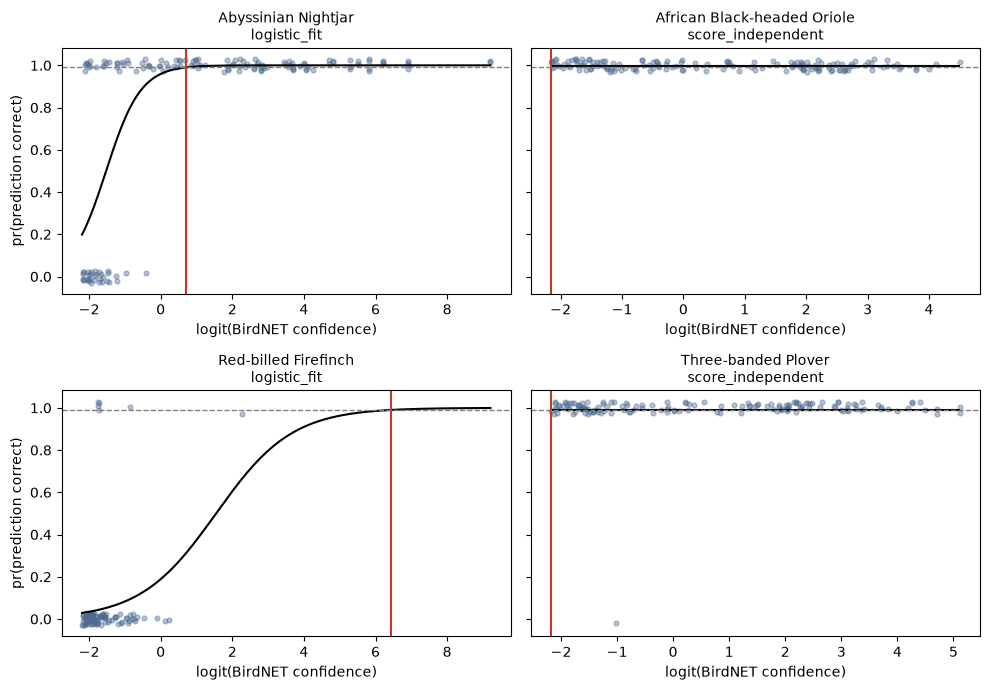

In [6]:
fig = plot_calibration_curves(validations, results, settings, rng)

## 5. Assign observations to all predictions

`observation` holds the species common name when the prediction is accepted, and is empty otherwise.
`p_correct` is the model's probability that the prediction is correct. It is empty where we have no
valid model.

In [7]:
labelled = label_predictions(predictions, thresholds, settings)
summarise(labelled, thresholds)

,predictions,observations,status,confidence_threshold,share_accepted
common_name,,,,,
Abyssinian Nightjar,10187,3147,logistic_fit,0.666638,0.309
African Black-headed Oriole,18054,17646,score_independent,0.104000,0.977
Red-billed Firefinch,235,0,logistic_fit,0.998380,0.000
Three-banded Plover,1015,1001,score_independent,0.102000,0.986
